# Birks' Constant (kb) Loss Scanning & Bias Diagnostics

This simplified notebook allows running Birks' constant ($k_b$) scans to analyze how well the likelihood minima align with the true nominal target value ($k_b = 0.0486$).

It sweeps and evaluates 8 distinct configurations across:
1. **Target**: Normal (Stochastic) vs. Probabilistic (Sampling)
2. **Guess**: Corrected (excess_offset=100 e-) vs. Uncorrected (excess_offset=0 e-)
3. **Loss Hits**: First-hit only vs. All hits

In [ ]:
%reload_ext autoreload
%autoreload 2
import sys
import os
import jax
import jax.numpy as jnp
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm

# Force JAX on CPU
jax.config.update('jax_platform_name', 'cpu')

project_root = '/sdf/group/neutrino/pgranger/larnd-sim-jax/src'
if project_root not in sys.path:
    sys.path.insert(0, project_root)

%cd /sdf/group/neutrino/pgranger/larnd-sim-jax

from larndsim.consts_jax import build_params_class, load_detector_properties, load_lut
from larndsim.losses_jax import adc2charge
from larndsim.fee_jax import get_adc_values, digitize
from larndsim.sim_jax import simulate_wfs
from optimize.strategies import (
    LUTSimulation, LUTProbabilisticSimulation,
    ProbabilisticLossStrategy, LUTProbabilisticSamplingSimulation
)
from optimize.dataio import TracksDataset, DataLoader
from optimize.ranges import ranges

/sdf/home/p/pgranger/.local/lib/python3.10/site-packages/IPython/core/magics/osm.py:417: UserWarning: This is now an optional IPython functionality, setting dhist requires you to install the `pickleshare` library.
  self.shell.db['dhist'] = compress_dhist(dhist)[-100:]


/sdf/group/neutrino/pgranger/larnd-sim-jax


: 

: 

In [3]:
INPUT_FILE = '/sdf/data/neutrino/cyifan/diffsim_input/true_through_muon_edep_10cm_vol1cm.h5'
LUT_FILE = 'src/larndsim/detector_properties/response_44_v2a_full_tick.npz'
DET_PROPS = 'src/larndsim/detector_properties/module0.yaml'
PIXEL_LAYOUTS = 'src/larndsim/pixel_layouts/multi_tile_layout-2.4.16_v4.yaml'

RELEVANT_PARAMS = ['Ab', 'kb', 'lifetime', 'tran_diff', 'long_diff', 'eField', 'shift_x', 'shift_y', 'shift_z']
ELECTRON_SAMPLING_RESOLUTION = 0.01
NUMBER_PIX_NEIGHBORS = 4
SIGNAL_LENGTH = 150

ParamsClass = build_params_class(RELEVANT_PARAMS)
ref_params = load_detector_properties(ParamsClass, DET_PROPS, PIXEL_LAYOUTS)
ref_params = ref_params.replace(
    electron_sampling_resolution=ELECTRON_SAMPLING_RESOLUTION,
    number_pix_neighbors=NUMBER_PIX_NEIGHBORS,
    signal_length=SIGNAL_LENGTH,
    time_window=SIGNAL_LENGTH,
    fee_paths_scaling=100
)

response, ref_params = load_lut(LUT_FILE, ref_params)
print("Response LUT Loaded.")

INFO:larndsim.consts_jax:Loading response from npz file


Response LUT Loaded.


In [4]:
# Load track data
dataset = TracksDataset(filename=INPUT_FILE, nevents=5, electron_sampling_resolution=ELECTRON_SAMPLING_RESOLUTION)
dataloader = DataLoader(dataset, batch_size=-1)
tracks_batch = dataloader[0]
track_fields = dataset.get_track_fields()

# Reshape to 2D segments
tracks_all = tracks_batch.reshape(-1, len(track_fields))

# Use the first 1000 segments to ensure enough hits for the scan while remaining fast
tracks = jax.device_put(tracks_all[:1000])
print(f"Loaded {tracks.shape[0]} track segments.")

INFO:optimize.dataio:-- The used simulation data includes a total track length of 148.8118371963501 cm.
INFO:optimize.dataio:-- The number of simulation batches is 3.


Loaded 1000 track segments.


In [5]:
stoch_strategy = LUTSimulation(response)
prob_sampling_strategy = LUTProbabilisticSamplingSimulation(response)

# Nominal params for generating target data (kb = 0.0486)
nominal_kb = 0.0486
current_params = ref_params.replace(
    Ab=0.8, kb=nominal_kb, lifetime=2200.0,
    tran_diff=8.8e-6, long_diff=4.0e-6, eField=0.5,
    shift_x=0.0, shift_y=0.0, shift_z=0.0,
    excess_offset=100.0, smooth_sigma_scale=1.00
)

N_DRAWS = 50
print(f"Generating {N_DRAWS} draws for normal and probabilistic targets...")

stoch_targets = []
prob_targets = []

for i in tqdm(range(N_DRAWS), desc="Generating Targets"):
    # 1. Stochastic Target (Normal Target)
    pred_stoch = stoch_strategy.predict(current_params, tracks, track_fields, rngkey=i+1)
    stoch_targets.append({
        'pixel_id': pred_stoch['hit_pixels'],
        'ticks': pred_stoch['ticks'],
        'adcs': pred_stoch['adcs']
    })

    # 2. Probabilistic Target (Probabilistic Target via Sampling)
    pred_prob_sample = prob_sampling_strategy.predict(current_params, tracks, track_fields, rngkey=i+1000)
    prob_targets.append({
        'pixel_id': pred_prob_sample['hit_pixels'],
        'ticks': pred_prob_sample['ticks'],
        'adcs': pred_prob_sample['adcs']
    })

print(f"Target generation complete: {len(stoch_targets)} stoch and {len(prob_targets)} prob targets ready.")

Generating 50 draws for normal and probabilistic targets...


Generating Targets:   0%|          | 0/50 [00:00<?, ?it/s]/usr/local/lib/python3.10/dist-packages/jax/_src/numpy/array_methods.py:122: UserWarning: Explicitly requested dtype <class 'jax.numpy.int64'> requested in astype is not available, and will be truncated to dtype int32. To enable more dtypes, set the jax_enable_x64 configuration option or the JAX_ENABLE_X64 shell environment variable. See https://github.com/jax-ml/jax#current-gotchas for more.
  return lax_numpy.astype(self, dtype, copy=copy, device=device)
/sdf/group/neutrino/pgranger/larnd-sim-jax/src/larndsim/detsim_jax.py:274: UserWarning: Explicitly requested dtype <class 'jax.numpy.int64'> requested in array is not available, and will be truncated to dtype int32. To enable more dtypes, set the jax_enable_x64 configuration option or the JAX_ENABLE_X64 shell environment variable. See https://github.com/jax-ml/jax#current-gotchas for more.
  return jnp.where(outside, jnp.array(-1, dtype=jnp.int64), pid)
INFO:larndsim.sim_jax:P

: 

: 

: 

In [5]:
prob_strategy = LUTProbabilisticSimulation(response)

# kb scan grid (Birks' constant nominal = 0.0486)
kb_vals = np.array([0.035, 0.038, 0.041, 0.044, 0.046, 0.0486, 0.051, 0.054, 0.057, 0.060, 0.063, 0.066])

# Set up the 8 test configurations
combinations = [
    {"target": "Normal (Stochastic)", "guess": "Corrected (excess_offset=100)", "first_hit_only": True},
    {"target": "Normal (Stochastic)", "guess": "Corrected (excess_offset=100)", "first_hit_only": False},
    {"target": "Normal (Stochastic)", "guess": "Uncorrected (excess_offset=0)", "first_hit_only": True},
    {"target": "Normal (Stochastic)", "guess": "Uncorrected (excess_offset=0)", "first_hit_only": False},
    {"target": "Probabilistic (Sampling)", "guess": "Corrected (excess_offset=100)", "first_hit_only": True},
    {"target": "Probabilistic (Sampling)", "guess": "Corrected (excess_offset=100)", "first_hit_only": False},
    {"target": "Probabilistic (Sampling)", "guess": "Uncorrected (excess_offset=0)", "first_hit_only": True},
    {"target": "Probabilistic (Sampling)", "guess": "Uncorrected (excess_offset=0)", "first_hit_only": False},
]

results = {i: [] for i in range(len(combinations))}

for kb in tqdm(kb_vals, desc="Scanning kb"):
    # Predict guesses for both corrected and uncorrected configurations
    params_corrected = current_params.replace(kb=float(kb), excess_offset=100.0, smooth_sigma_scale=1.00)
    params_uncorrected = current_params.replace(kb=float(kb), excess_offset=0.0, smooth_sigma_scale=1.00)

    pred_corrected = prob_strategy.predict(params_corrected, tracks, track_fields, rngkey=42)
    pred_uncorrected = prob_strategy.predict(params_uncorrected, tracks, track_fields, rngkey=42)

    for idx, comb in enumerate(combinations):
        first_hit = comb["first_hit_only"]
        strategy = ProbabilisticLossStrategy(first_hit_only=first_hit)

        # Select target dataset
        targets = stoch_targets if comb["target"] == "Normal (Stochastic)" else prob_targets

        # Select prediction and parameters
        if "Corrected" in comb["guess"]:
            pred = pred_corrected
            params = params_corrected
        else:
            pred = pred_uncorrected
            params = params_uncorrected

        # Calculate average NLL across all draws
        nlls = []
        for target in targets:
            nll, _ = strategy.compute(params, pred, target)
            nlls.append(float(nll))
        results[idx].append(np.mean(nlls))

print("kb Scan Complete.")


Scanning kb:   0%|                                       | 0/12 [00:00<?, ?it/s]


Scanning kb:   8%|██▌                           | 1/12 [01:45<19:25, 105.96s/it]


Scanning kb:  17%|█████▏                         | 2/12 [03:20<16:30, 99.02s/it]


Scanning kb:  25%|███████▊                       | 3/12 [04:53<14:29, 96.56s/it]


Scanning kb:  33%|██████████▎                    | 4/12 [06:11<11:53, 89.20s/it]


Scanning kb:  42%|████████████▉                  | 5/12 [07:30<09:58, 85.50s/it]

... (5 outputs left out)


Scanning kb:  92%|███████████████████████████▌  | 11/12 [15:16<01:18, 78.65s/it]


Scanning kb: 100%|██████████████████████████████| 12/12 [16:41<00:00, 80.56s/it]


Scanning kb: 100%|██████████████████████████████| 12/12 [16:41<00:00, 83.48s/it]

kb Scan Complete.


=== Summary of Likelihood Minima ===
True target kb value = 0.0486

Target                    | Guess                        | Hits     | Min kb | Bias   
--------------------------------------------------------------------------------
Normal (Stochastic)       | Corrected (excess_offset=100) | 1st only | 0.0510 | +0.0024
Normal (Stochastic)       | Corrected (excess_offset=100) | All      | 0.0486 | +0.0000
Normal (Stochastic)       | Uncorrected (excess_offset=0) | 1st only | 0.0510 | +0.0024
Normal (Stochastic)       | Uncorrected (excess_offset=0) | All      | 0.0486 | +0.0000
Probabilistic (Sampling)  | Corrected (excess_offset=100) | 1st only | 0.0486 | +0.0000
Probabilistic (Sampling)  | Corrected (excess_offset=100) | All      | 0.0486 | +0.0000
Probabilistic (Sampling)  | Uncorrected (excess_offset=0) | 1st only | 0.0486 | +0.0000
Probabilistic (Sampling)  | Uncorrected (excess_offset=0) | All      | 0.0486 | +0.0000


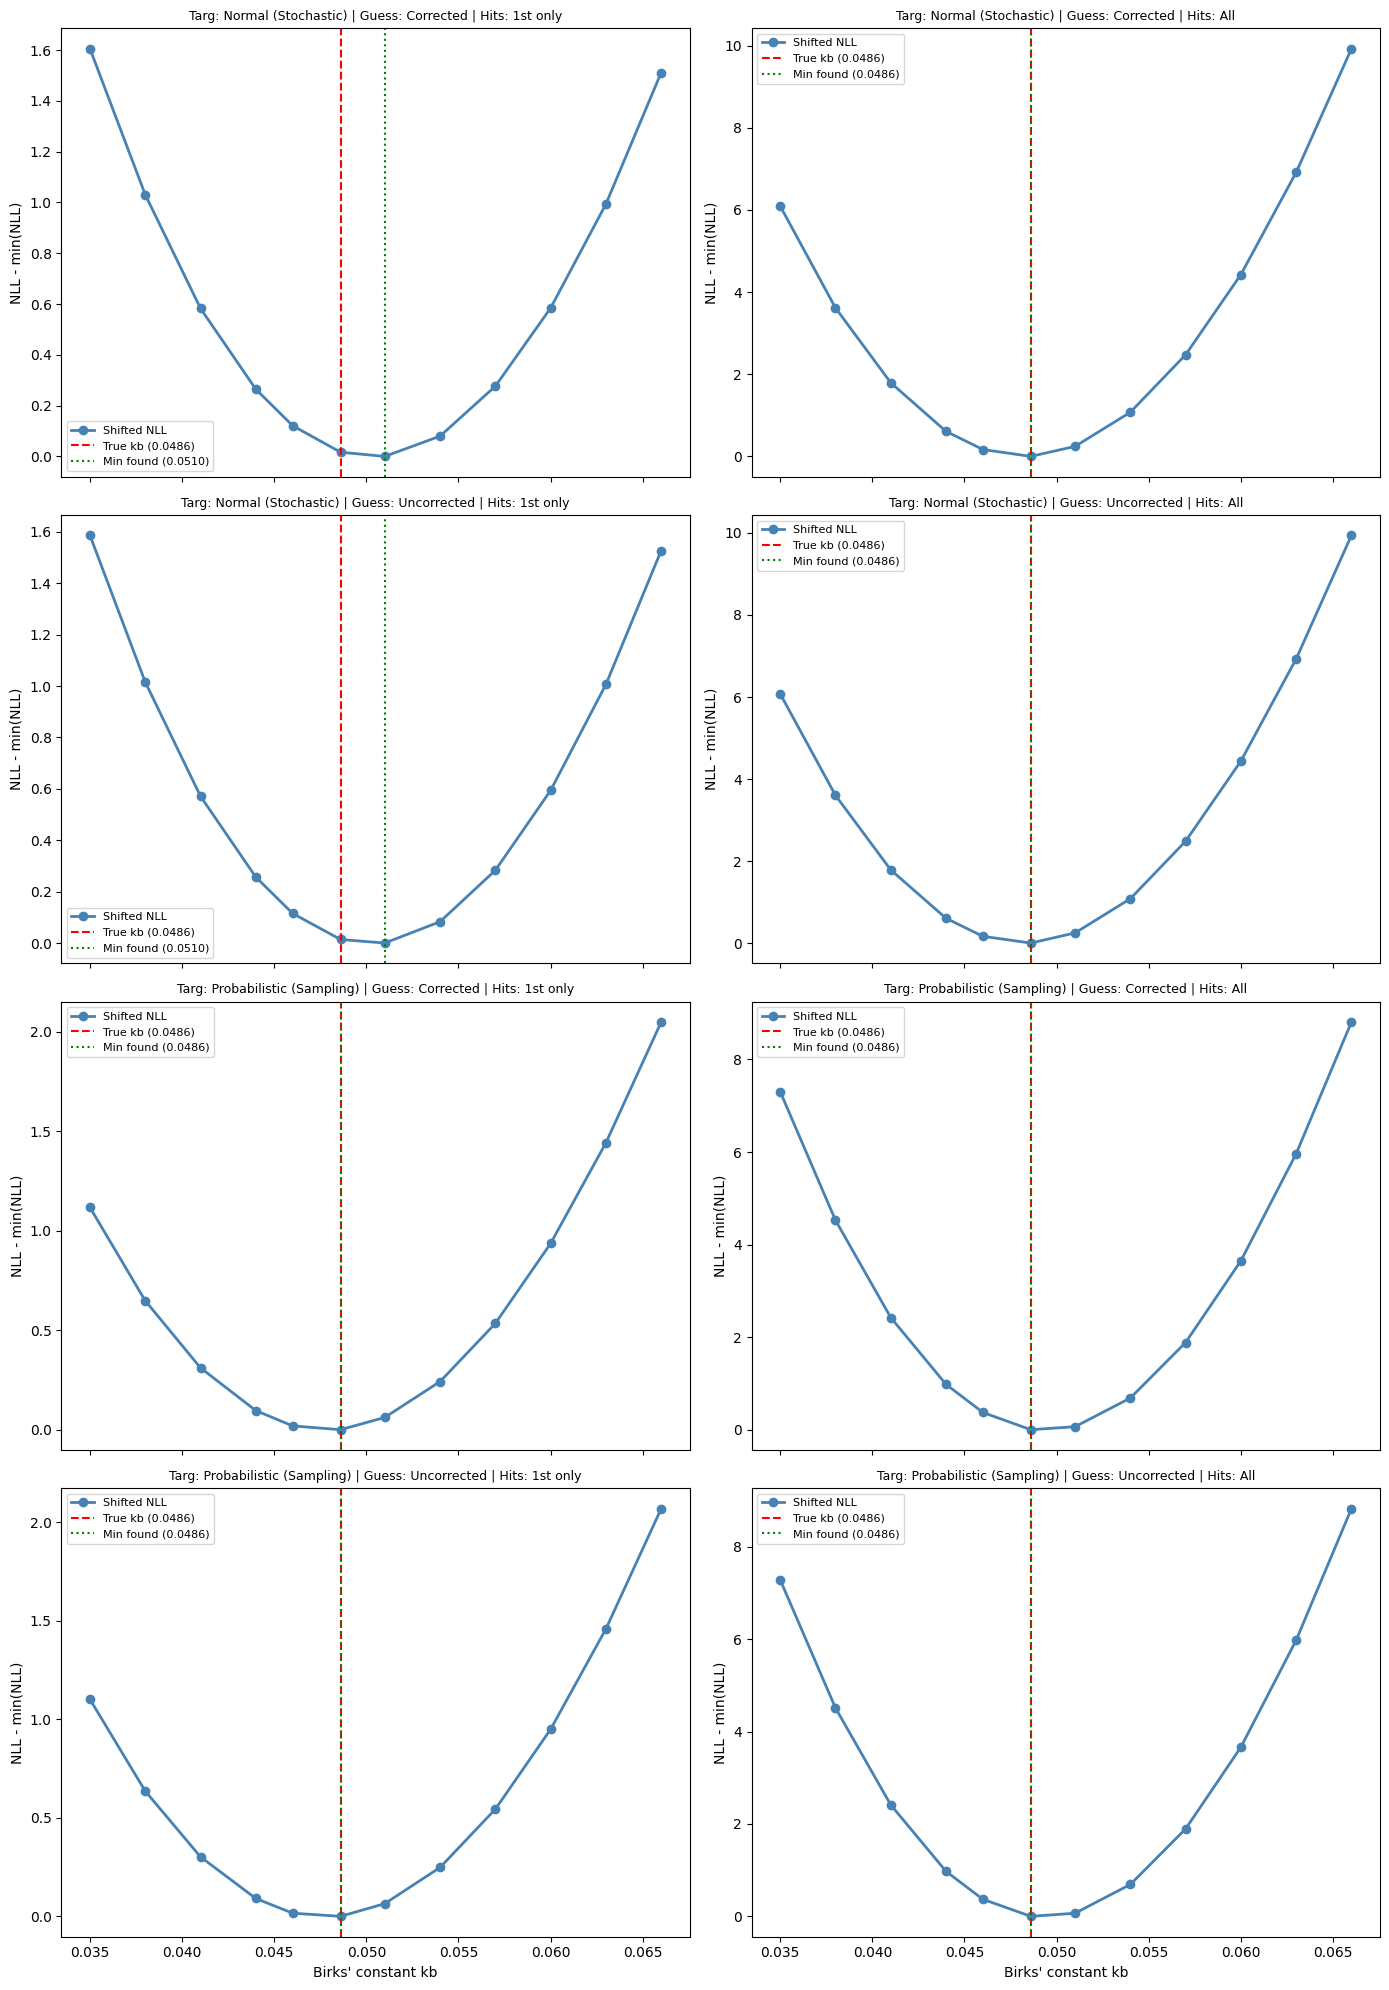

In [6]:
# Plotting Shifted NLL Curves for all 8 combinations
fig, axes = plt.subplots(4, 2, figsize=(14, 20), sharex=True)
axes_flat = axes.ravel()

print("=== Summary of Likelihood Minima ===")
print(f"True target kb value = {nominal_kb:.4f}\n")
print(f"{'Target':25s} | {'Guess':28s} | {'Hits':8s} | {'Min kb':6s} | {'Bias':7s}")
print("-" * 80)

for idx, comb in enumerate(combinations):
    nll_vals = np.array(results[idx])
    min_idx = np.argmin(nll_vals)
    min_kb = kb_vals[min_idx]
    bias = min_kb - nominal_kb
    
    hits_str = "1st only" if comb['first_hit_only'] else "All"
    print(f"{comb['target']:25s} | {comb['guess']:28s} | {hits_str:8s} | {min_kb:.4f} | {bias:+.4f}")

    # Plot
    ax = axes_flat[idx]
    # Shift NLL to start at min=0 for shape comparison
    nll_shifted = nll_vals - nll_vals.min()
    ax.plot(kb_vals, nll_shifted, marker='o', color='steelblue', lw=2, label='Shifted NLL')
    ax.axvline(nominal_kb, color='red', linestyle='--', label=f'True kb ({nominal_kb:.4f})')
    ax.axvline(min_kb, color='green', linestyle=':', label=f'Min found ({min_kb:.4f})')
    ax.set_title(f"Targ: {comb['target']} | Guess: {'Corrected' if 'Corrected' in comb['guess'] else 'Uncorrected'} | Hits: {hits_str}", fontsize=9)
    ax.set_ylabel("NLL - min(NLL)")
    if idx >= 6:
        ax.set_xlabel("Birks' constant kb")
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()